###Q1. What percentage of customers placed more than one order on the Olist platform?
```sql
/*count of unique customers(distinct customer_unique_id)*/
SELECT COUNT(DISTINCT b.customer_unique_id)
FROM olist_orders a
     JOIN olist_customers b ON a.customer_id = b.customer_id
WHERE a.order_status = 'delivered'
```
OUTPUT : (Count of total unique customers) 93358
```sql
/*count of unique customers who have more than 1 orders*/
SELECT COUNT(*)
FROM (SELECT b.customer_unique_id AS customer_id,
             COUNT(DISTINCT a.order_id) AS orders
     FROM olist_orders a
     JOIN olist_customers b
	 ON a.customer_id = b.customer_id
     WHERE a.order_status = 'delivered'
     GROUP BY b.customer_unique_id
     HAVING COUNT(DISTINCT a.order_id) > 1
) AS total_repeated_customers
```
OUTPUT : (Repeated customers) 2801

>**Insight** : Only 3% of the total customers make repeat purchase from the Olist platform.


###Q2. How do customer review scores differ between on-time and late deliveries?
```sql
SELECT a.delivery_status,
       ROUND(AVG(b.review_score), 2) AS avg_review_score
FROM olist_orders a
     JOIN olist_reviews b
	 ON a.order_id = b.order_id
WHERE a.delivery_status IS NOT NULL
GROUP BY a.delivery_status
ORDER BY avg_review_score DESC
```
OUTPUT :

| delivery_status | avg_review_score |
|---|---|
| early | 4.29 |
| on-time | 4.03 |
| slightly-late | 3.29 |
| late | 1.85 |



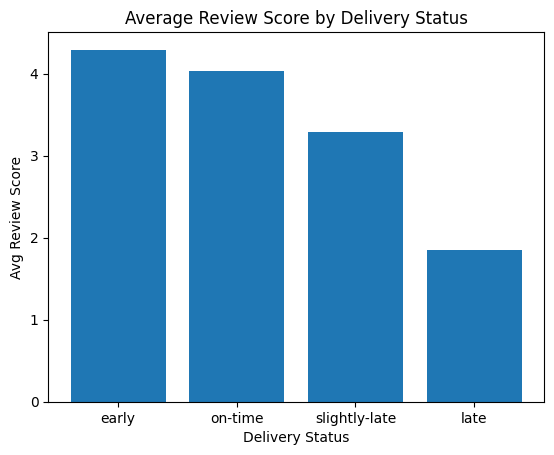

In [ ]:
import matplotlib.pyplot as plt

status = ["early", "on-time", "slightly-late", "late"]
score = [4.29, 4.03, 3.29, 1.85]

plt.bar(status, score)
plt.title("Average Review Score by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Avg Review Score")
plt.show()


>**Insight**: Review scores drop sharply as delivery gets later, from 4.29 for early deliveries to just 1.85 for late ones.

###Q3. Which states have the slowest deliveres?
**PART A (Low Volumne states)**

```sql
--States with fewer than 1,000 orders are treated as low-volume.
SELECT b.customer_state,
       COUNT(*) AS total_orders,
       SUM(CASE WHEN a.delivery_status = 'late' THEN 1 ELSE 0 END) AS late_orders,
	   ROUND(100.0* SUM(CASE WHEN a.delivery_status = 'late' THEN 1 ELSE 0 END)/COUNT(*), 2) AS late_pct
FROM olist_orders a
     JOIN olist_customers b
	 ON a.customer_id = b.customer_id
WHERE a.delivery_status IS NOT NULL
GROUP BY b.customer_state
HAVING COUNT(*) < 1000
ORDER BY late_pct DESC
```

OUTPUT :

| customer_state | total_orders | late_orders | late_pct |
|---|---|---|---|
| AL | 397 | 69 | 17.38 |
| SE | 335 | 43 | 12.84 |
| MA | 717 | 92 | 12.83 |
| RR | 41 | 5 | 12.20 |
| PI | 476 | 47 | 9.87 |
| PA | 946 | 90 | 9.51 |
| PB | 517 | 40 | 7.74 |
| RN | 474 | 35 | 7.38 |
| TO | 274 | 20 | 7.30 |
| MS | 701 | 46 | 6.56 |
| MT | 886 | 37 | 4.18 |
| AC | 80 | 2 | 2.50 |
| RO | 243 | 4 | 1.65 |
| AP | 67 | 1 | 1.49 |
| AM | 145 | 2 | 1.38 |


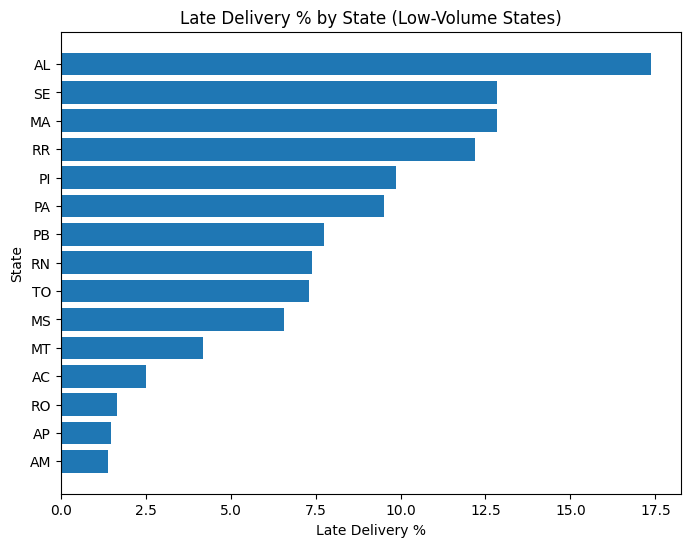

In [ ]:
import matplotlib.pyplot as plt

states = ["AL","SE","MA","RR","PI","PA","PB","RN","TO","MS","MT","AC","RO","AP","AM"]
late_pct = [17.38,12.84,12.83,12.20,9.87,9.51,7.74,7.38,7.30,6.56,4.18,2.50,1.65,1.49,1.38]

plt.figure(figsize=(8,6))
plt.barh(states, late_pct)
plt.gca().invert_yaxis()
plt.title("Late Delivery % by State (Low-Volume States)")
plt.xlabel("Late Delivery %")
plt.ylabel("State")
plt.show()


> **Insight:** Among low-volume states, Alagoas (AL) has the highest late delivery rate at 17.38%, followed by Sergipe (SE) and Maranhao (MA) at around 12.8%. In total, 10 out of 15 states have more than 5% late deliveries. On the other hand, Amazonas (AM), Amapa (AP) and Rondonia (RO) perform best, with late rates below 2%. Note that states like RR, AP and AC have very few orders, so their percentages may not be fully reliable.

> **Suggestion:** Olist should first focus on AL, PA and MA, by improving logistics partners and checking delivery routes in these states.


**PART B (High Volumne states)**

```sql
SELECT b.customer_state,
       COUNT(*) AS total_orders,
       SUM(CASE WHEN a.delivery_status = 'late' THEN 1 ELSE 0 END) AS late_orders,
	   ROUND(100.0* SUM(CASE WHEN a.delivery_status = 'late' THEN 1 ELSE 0 END)/COUNT(*), 2) AS late_pct
FROM olist_orders a
     JOIN olist_customers b
	 ON a.customer_id = b.customer_id
WHERE a.delivery_status IS NOT NULL
GROUP BY b.customer_state
HAVING COUNT(*) >= 1000
ORDER BY late_pct DESC
```

OUTPUT :

| customer_state | total_orders | late_orders | late_pct |
|---|---|---|---|
| CE | 1279 | 146 | 11.42 |
| RJ | 12350 | 1198 | 9.70 |
| BA | 3256 | 303 | 9.31 |
| ES | 1995 | 158 | 7.92 |
| PE | 1593 | 124 | 7.78 |
| SC | 3546 | 200 | 5.64 |
| GO | 1957 | 91 | 4.65 |
| RS | 5344 | 242 | 4.53 |
| DF | 2080 | 79 | 3.80 |
| MG | 11354 | 339 | 2.99 |
| SP | 40494 | 1128 | 2.79 |
| PR | 4923 | 123 | 2.50 |



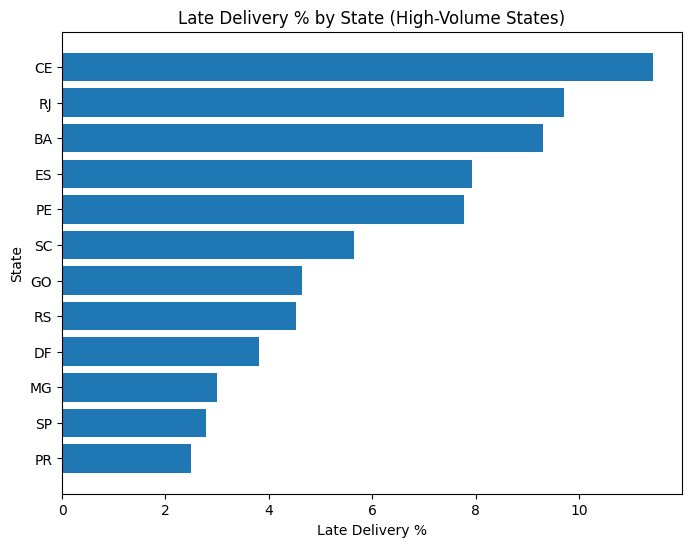

In [ ]:
import matplotlib.pyplot as plt

states = ["CE","RJ","BA","ES","PE","SC","GO","RS","DF","MG","SP","PR"]
late_pct = [11.42,9.70,9.31,7.92,7.78,5.64,4.65,4.53,3.80,2.99,2.79,2.50]

plt.figure(figsize=(8,6))
plt.barh(states, late_pct)
plt.gca().invert_yaxis()
plt.title("Late Delivery % by State (High-Volume States)")
plt.xlabel("Late Delivery %")
plt.ylabel("State")
plt.show()

> **Insight:** Among high-volume states, Ceara (CE) has the highest late delivery rate at 11.42%, followed by Rio de Janeiro (RJ) at 9.70% and Bahia (BA) at 9.31%. Six out of 12 states have more than 5% late deliveries. RJ has the highest number of late orders (1,198) of all states in this group, so even a small improvement there will have a big impact. On the other hand, Parana (PR), Sao Paulo (SP) and Minas Gerais (MG) perform best, with late rates below 3%, even though SP handles over 40,000 orders.

> **Suggestion:** Olist should prioritise RJ first, since it has the most late orders, and then CE and BA. The logistics practices of SP, MG and PR can be used as a model to improve these states.

>**Overall** - Late deliveries are concentrated in the north-east region of Brazil, so regional logistics there needs the most attention.

###Q4. Which categories have the least ratings ?

**Top 10 products with their number of items sold** :
```sql
SELECT b.product_category,
       COUNT(*) AS items_count
FROM olist_order_items a
     JOIN olist_products b
	 ON a.product_id = b.product_id
GROUP BY b.product_category
ORDER BY items_count DESC
LIMIT 10
```
OUTPUT :

| Product Category | Items Count |
|---|---|
| bed_bath_table | 11115 |
| health_beauty | 9670 |
| sports_leisure | 8641 |
| furniture_decor | 8334 |
| computers_accessories | 7827 |
| housewares | 6964 |
| watches_gifts | 5991 |
| telephony | 4545 |
| garden_tools | 4347 |
| auto | 4235 |


**Top 5 Product categories revenue wise** :
```sql
SELECT b.product_category,
       SUM(price) AS revenue
FROM olist_order_items a
     JOIN olist_products b
	 ON a.product_id = b.product_id
GROUP BY b.product_category
ORDER BY revenue DESC
LIMIT 5
```
OUTPUT :

| Product Category | Revenue (R$) |
|---|---|
| health_beauty | 1,258,681.34 |
| watches_gifts | 1,205,005.68 |
| bed_bath_table | 1,036,988.68 |
| sports_leisure | 988,048.97 |
| computers_accessories | 911,954.32 |

**Product categories who have sold more than 1000 items but still have low review score** :
```sql
SELECT c.product_category,
       COUNT(*) AS items_sold,
       ROUND(AVG(a.review_score), 2) AS avg_score
FROM olist_reviews a
     JOIN olist_order_items b ON a.order_id = b.order_id
	 JOIN olist_products c ON b.product_id = c.product_id
GROUP BY c.product_category
HAVING COUNT(*) >= 1000
ORDER BY avg_score
```

OUTPUT :
| Product Category | Items Count | Avg Rating |
|---|---|---|
| office_furniture | 1677 | 3.49 |
| unknown | 1613 | 3.83 |
| bed_bath_table | 10982 | 3.90 |
| furniture_decor | 8250 | 3.90 |
| computers_accessories | 7782 | 3.93 |
| telephony | 4512 | 3.95 |
| baby | 3040 | 4.01 |
| watches_gifts | 5940 | 4.02 |
| consoles_games | 1126 | 4.02 |
| electronics | 2748 | 4.04 |
| housewares | 6918 | 4.05 |
| garden_tools | 4315 | 4.05 |
| auto | 4192 | 4.06 |
| sports_leisure | 8581 | 4.11 |
| fashion_bags_accessories | 2020 | 4.14 |
| health_beauty | 9588 | 4.14 |
| cool_stuff | 3762 | 4.15 |
| toys | 4083 | 4.16 |
| perfumery | 3405 | 4.17 |
| pet_shop | 1937 | 4.18 |
| stationery | 2499 | 4.20 |
| luggage_accessories | 1088 | 4.32 |

>**Insight** : 1. office_furniture has the lowest average rating (3.49), far below all other categories.
2. bed_bath_table is the top-selling category and 3rd in revenue, but its rating is only 3.90. Biggest business impact.
3. furniture_decor (3.90) and computers_accessories (3.93) also combine high volume with below-average ratings.

>**Suggestion** : Prioritise bed_bath_table (largest impact) and office_furniture (lowest rating), and check delivery delays as a possible cause.




###Q4. Which sellers have the least ratings
(SellerID's are shortened to the first 5 characters for readability)


**Top 10 sellers by items sold** :
```sql
SELECT seller_id,
       COUNT(*) AS total_items
FROM olist_order_items
GROUP BY seller_id
ORDER BY total_items DESC
LIMIT 10
```

OUTPUT :  
| Seller ID | Total Items Sold |
|---|---|
| 65602 | 2033 |
| 4a3ca | 1987 |
| 1f50f | 1931 |
| cc419 | 1775 |
| da862 | 1551 |
| 955fe | 1499 |
| 1025f | 1428 |
| 7c67e | 1364 |
| ea848 | 1203 |
| 7a67c | 1171 |

**top 10 sellers by revenue**
```sql
SELECT seller_id,
       SUM(price) AS revenue
FROM olist_order_items
GROUP BY seller_id
ORDER BY revenue DESC
LIMIT 10
```

OUTPUT :
| Seller ID | Revenue (R$) |
|---|---|
| 4869f | 229,472.63 |
| 53243 | 222,776.05 |
| 4a3ca | 200,472.92 |
| fa1c1 | 194,042.03 |
| 7c67e | 187,923.89 |
| 7e93a | 176,431.87 |
| da862 | 160,236.57 |
| 7a67c | 141,745.53 |
| 1025f | 138,968.55 |
| 955fe | 135,171.70 |


**sellers with lowest ratings(1000+ items sold)** :
```sql
SELECT b.seller_id,
       ROUND(AVG(a.review_score), 2) AS avg_ratings
FROM olist_reviews a
     JOIN olist_order_items b
	 USING (order_id)
GROUP BY b.seller_id
HAVING COUNT(*) > 1000
ORDER BY avg_ratings
LIMIT 10
```

OUTPUT
| Seller ID | Avg Rating |
|---|---|
| 7c67e | 3.34 |
| 4a3ca | 3.80 |
| 1025f | 3.85 |
| 65602 | 3.91 |
| ea848 | 3.95 |
| 1f50f | 3.99 |
| 8b321 | 4.00 |
| 955fe | 4.05 |
| cc419 | 4.06 |
| da862 | 4.07 |


>**Insight** : 1. Seller 7c67e has the lowest rating (3.34) while being 5th in revenue and selling 1,364 items (Highest-risk seller).
2. Seller 4a3ca is 3rd in revenue and 2nd in items sold, but its rating is only 3.80.
3. Seller 65602 sells the most items (2,033) with a 3.91 rating, so the most customers are affected here.
Most other high-volume sellers sit between 3.9 and 4.1, so 7c67e is the real outlier.

>**Suggestion** : Investigate 7c67e first, then 4a3ca, and check delivery delays as a possible cause.